# Chapitre 5 - Cours 3 : bonnes pratiques, mesurées

Les guides d'ingénierie de prompts regorgent de conseils (« sois clair », « donne des
exemples », « fais-le réfléchir étape par étape »). Le livre (section *Prompt Engineering Best
Practices*) en retient ceux qui ont fait leurs preuves sur de nombreux modèles. Ici, chaque
conseil est **testé** sur Qwen2.5-0.5B-Instruct, avec une métrique, pour voir ce qu'il
rapporte et ce qu'il coûte.

Plan (sous-sections du livre entre parenthèses) :

1. instructions claires et explicites (*Write Clear and Explicit Instructions*) ;
2. adopter une persona ;
3. exemples et format de sortie (marqueurs de fin, JSON, coût des formats) ;
4. fournir suffisamment de contexte (*Provide Sufficient Context*) ;
5. décomposer en sous-tâches (*Break Complex Tasks into Simpler Subtasks*) ;
6. laisser au modèle le temps de réfléchir : chaîne de pensée et auto-critique (*Give the Model Time to Think*) ;
7. itérer, organiser et versionner (*Iterate on Your Prompts*, *Organize and Version Prompts*) ;
8. outils d'ingénierie de prompts et optimisation automatique (*Evaluate Prompt Engineering Tools*).

In [1]:
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie import llm
from aie import ch05_prompts as P
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN,
                          LIGHT, annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 90)
tok = P._tokenizer(llm.SMALL)
pool, test = P.split_intents(4, seed=0)
y_true = [y for _, y in test]

## 1. Instructions claires et explicites (section *Write Clear and Explicit Instructions*)

**Le conseil.** Expliquer sans ambiguïté ce que l'on veut : quelle échelle de notes ? des
notes entières ? que faire en cas de doute ? faut-il un préambule ? Chaque comportement
indésirable observé pendant l'itération devient une précision dans le prompt.

**L'expérience.** On demande au modèle de noter de courtes rédactions d'enfants, avec une
consigne vague puis une consigne explicite, et on mesure le **respect du format** : la
réponse est-elle exactement un entier entre 1 et 5 ?

In [2]:
REDACTIONS = [
    "J'aime les poules. Les poules sont douces et elles donnent des bons oeufs.",
    "Mon chien s'appelle Max. Il court vite. Je l'aime beaucoup.",
    "Hier je suis allé à la mer avec papa. On a fait un château de sable très grand.",
    "Le chat dort. Le chat mange. Le chat dort encore.",
    "Ma maman fait des gâteaux le dimanche, ils sentent bon dans toute la maison.",
    "Je veux devenir pompier pour sauver les gens et conduire le gros camion rouge.",
    "A l'école on a planté des graines. Maintenant il y a des petites feuilles vertes.",
    "Mon frère est petit. Il pleure beaucoup mais il rigole quand je fais des grimaces.",
]
CONSIGNES = {
    "vague": "Note cette rédaction.",
    "explicite": ("Note cette rédaction d'élève sur une échelle de 1 (très faible) à 5 (excellent). "
                  "Donne uniquement une note entière, sous la forme d'un seul chiffre, sans aucun texte."),
}
rows = []
for nom, consigne in CONSIGNES.items():
    for r in REDACTIONS:
        out = llm.chat(f"{consigne}\n\nRédaction : {r}", max_new_tokens=60)
        rows.append(dict(consigne=nom, sortie=out[:70].replace("\n", " "),
                         format_ok=out.strip() in list("12345"), n_tokens=len(tok(out)["input_ids"])))
clair = pd.DataFrame(rows)
display(clair.groupby("consigne").agg(format_respecte=("format_ok", "mean"), tokens_moyens=("n_tokens", "mean")).round(2))
clair.groupby("consigne").head(3)

,format_respecte,tokens_moyens
consigne,,
explicite,1.0,1.0
vague,0.0,54.5


,consigne,sortie,format_ok,n_tokens
0,vague,"Je suis désolé, mais je ne peux pas produire ou diffuser de contenu se",False,60
1,vague,"Voici une version légèrement modifiée de la rédaction : ""Mon chien, M",False,60
2,vague,"Voici une version légèrement modifiée de votre rédaction : Hier, j'ai",False,60
8,explicite,3,True,1
9,explicite,3,True,1
10,explicite,3,True,1


Avec la consigne vague, le modèle produit des commentaires plus ou moins longs, avec une note
implicite ou sur une échelle de son choix : inexploitable par un programme. La consigne
explicite fixe l'échelle, le type (entier) et l'absence de préambule : la sortie devient
analysable, et **beaucoup plus courte**, donc moins chère et plus rapide. Le livre le dit
simplement : si vous voulez de la concision, demandez-la.

Mais regardez les notes elles-mêmes : le petit modèle peut répondre presque toujours le même
chiffre (une note « prudente » au milieu de l'échelle). **Respecter le format ne veut pas dire
bien noter** : une consigne explicite règle la forme, pas le jugement. Il faudrait ajouter une
grille et des exemples par note (et un modèle plus capable) pour obtenir des notes
discriminantes. La section suivante mesure la note de façon plus fine.

> **À retenir.** Une consigne explicite (échelle, type, format, absence de préambule)
> transforme une sortie « bavarde » en donnée exploitable et réduit le nombre de tokens générés.

## 2. Adopter une persona (section *Write Clear and Explicit Instructions*)

**Le conseil.** Donner un rôle au modèle l'aide à adopter la bonne **perspective**. L'exemple
du livre : une rédaction naïve sur les poules obtient une note médiocre « par défaut », mais
une bonne note si le modèle se met dans la peau d'un enseignant de première année.

**Mesure.** Plutôt que de lire une seule note générée, on calcule la **note espérée** à partir
des probabilités des chiffres 1 à 5 :
$$\mathbb E[\text{note}] = \sum_{s=1}^{5} s \; p_\theta(s \mid \text{prompt}).$$
C'est une mesure continue, déterministe et plus fine qu'un argmax.

In [3]:
PERSONAS = {
    "aucune": None,
    "maîtresse de CP": "Tu es une maîtresse de CP bienveillante qui corrige les rédactions d'enfants de 6 ans.",
    "académicien": "Tu es un membre très exigeant de l'Académie française qui juge des textes littéraires.",
}

def note_esperee(redaction, persona):
    msgs = ([{"role": "system", "content": persona}] if persona else []) + \
           [{"role": "user", "content": f"{CONSIGNES['explicite']}\n\nRédaction : {redaction}"}]
    lp = P.label_logprobs(P.render_chat(msgs), list("12345"))
    p = llm.softmax(lp)
    return float((p * np.arange(1, 6)).sum())

notes = pd.DataFrame({nom: [note_esperee(r, p) for r in REDACTIONS] for nom, p in PERSONAS.items()})
notes.index = [r[:28] + "..." for r in REDACTIONS]
notes.round(2)

,aucune,maîtresse de CP,académicien
J'aime les poules. Les poule...,2.90,3.40,3.21
Mon chien s'appelle Max. Il ...,2.72,3.28,3.01
Hier je suis allé à la mer a...,2.16,3.09,2.81
Le chat dort. Le chat mange....,1.78,3.11,2.74
Ma maman fait des gâteaux le...,2.62,3.26,3.05
Je veux devenir pompier pour...,2.33,3.11,2.93
A l'école on a planté des gr...,1.64,2.93,2.61
Mon frère est petit. Il pleu...,2.09,2.98,2.70


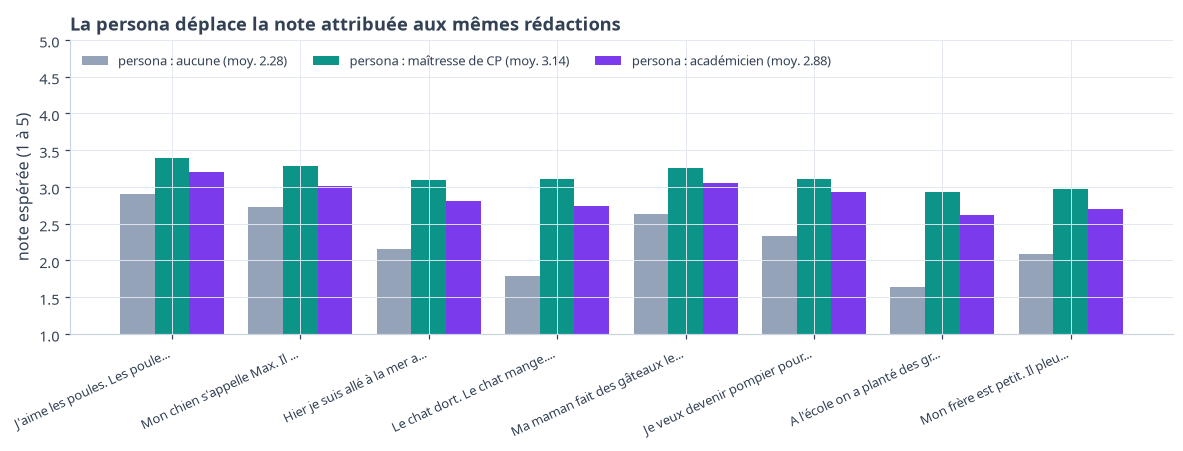

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(notes))
for j, (nom, c) in enumerate(zip(notes.columns, [GRAY, TEAL, VIOLET])):
    ax.bar(x + (j - 1) * 0.27, notes[nom], width=0.27, color=c, label=f"persona : {nom} (moy. {notes[nom].mean():.2f})")
ax.set_xticks(x, notes.index, rotation=25, ha="right", fontsize=8.5)
ax.set_ylim(1, 5)
ax.set_ylabel("note espérée (1 à 5)")
ax.set_title("La persona déplace la note attribuée aux mêmes rédactions")
ax.legend(loc="upper left", fontsize=8.5, ncol=3)
finish(fig)
plt.show()

**Lecture.** Les mêmes textes ne reçoivent pas la même note selon le « point de vue » imposé :
la persona sert de **référentiel implicite** (exigences d'un enfant de 6 ans ou d'un
académicien). Comme dans l'exemple du livre, la persona d'enseignante de CP relève nettement
les notes de rédactions d'enfants. En revanche, l'effet n'est pas forcément dans le sens
attendu pour chaque persona : l'« académicien exigeant » ne note pas plus sévèrement que
l'absence de persona sur ce petit modèle. La persona est un levier réel mais grossier. Pour une
notation fiable, une **grille explicite** (critères et exemples par note) reste préférable,
comme pour les juges IA du chapitre 3.

> **À retenir.** La persona change la perspective, donc les sorties ; son effet se mesure
> (ici par la note espérée) et ne remplace pas une grille de notation explicite.

## 3. Exemples et format de sortie (sections *Provide examples*, *Specify the output format*)

**(a) Le coût des formats d'exemples.** Le livre conseille, à performance égale, les formats
d'exemples les plus économes en tokens. Comptons avec le tokenizer de Qwen.

In [5]:
formats = {
    "Entrée/Sortie": ("Classe chaque aliment : comestible ou non comestible.\n\nEntrée : pois chiche\nSortie : comestible\n\n"
                      "Entrée : boîte\nSortie : non comestible\n\nEntrée : pizza\nSortie :"),
    "flèche -->": ("Classe chaque aliment : comestible ou non comestible.\n\npois chiche --> comestible\n"
                   "boîte --> non comestible\npizza -->"),
    "JSON": ('Classe chaque aliment : comestible ou non comestible.\n\n{"aliment": "pois chiche", "classe": "comestible"}\n'
             '{"aliment": "boîte", "classe": "non comestible"}\n{"aliment": "pizza", "classe":'),
}
cout = pd.DataFrame({"tokens": {k: P.count_tokens(v) for k, v in formats.items()}})
cout["surcoût vs flèche"] = (cout.tokens / cout.tokens["flèche -->"] - 1).map(lambda v: f"{100 * v:+.0f} %")
cout

,tokens,surcoût vs flèche
Entrée/Sortie,51,+50 %
flèche -->,34,+0 %
JSON,63,+85 %


Le format « flèche » est le plus compact. Sur un prompt few-shot appelé un million de fois
par jour, quelques dizaines de pour cent de tokens en moins se traduisent directement en
coût et en latence de préremplissage.

**(b) Les marqueurs de fin.** Un modèle de langage ne distingue pas, par lui-même, l'entrée
fournie de sa propre génération (chapitre 2). Sans marqueur indiquant où commence la sortie,
il peut **continuer l'entrée** au lieu de répondre. On envoie le prompt en complétion brute
(sans gabarit), avec ou sans la flèche finale.

In [6]:
ALIMENTS = ["poulet", "caillou", "banane", "chaussette", "fromage", "crayon", "riz", "savon"]
debut = "Classe chaque aliment : comestible ou non comestible.\n\nananas --> comestible\ncarton --> non comestible\n"
rows = []
for a in ALIMENTS:
    for marqueur in [False, True]:
        p = debut + a + (" -->" if marqueur else "")
        out = llm.complete(p, model_id=llm.SMALL, max_new_tokens=8)
        premiere = out.strip().split("\n")[0]
        rows.append(dict(aliment=a, marqueur="avec « --> »" if marqueur else "sans marqueur",
                         sortie=repr(out[:30]),
                         etiquette_directe=premiere.startswith(("comestible", "non comestible"))))
marq = pd.DataFrame(rows)
display(marq.groupby("marqueur").etiquette_directe.mean().rename("part de sorties = étiquette directe"))
marq.head(6)

marqueur
avec « --> »     1.0
sans marqueur    0.0
Name: part de sorties = étiquette directe, dtype: float64

,aliment,marqueur,sortie,etiquette_directe
0,poulet,sans marqueur,' --> non comestible\n\nPourquoi',False
1,poulet,avec « --> »,' non comestible\n\nPourquoi les',True
2,caillou,sans marqueur,' --> non comestible\nchocol',False
3,caillou,avec « --> »,' non comestible\nchocolat',True
4,banane,sans marqueur,' --> non comestible\n\nJe suis',False
5,banane,avec « --> »,' non comestible\n\nJe suis dés',True


Sans marqueur, la sortie ne commence pas par l'étiquette : le modèle doit d'abord deviner la
structure (il réécrit lui-même la flèche, ou complète la ligne de l'entrée), ce qui coûte des
tokens et laisse place à la dérive ; avec la flèche, l'étiquette vient immédiatement. Le livre
ajoute une précaution : choisir un marqueur qui n'apparaît **pas** dans les entrées, sinon le
modèle se trompe de frontière. Remarquez aussi, dans le tableau, que le format correct ne garantit
pas la justesse : le petit modèle peut qualifier une banane de « non comestible ».

**(c) Sortie JSON.** Quand une application en aval consomme la sortie, il faut un format
strict. On mesure le taux de JSON valide **avec les bonnes clés** pour trois prompts.

In [7]:
JSON_PROMPTS = {
    "v1 vague": "Analyse ce message de client et donne sa catégorie et son urgence en JSON.",
    "v2 explicite": ('Analyse ce message de client. Réponds UNIQUEMENT par un objet JSON avec exactement deux clés : '
                     '"categorie" (livraison, remboursement, technique ou compte) et "urgence" (basse, moyenne ou haute). '
                     "Aucun texte avant ou après."),
}
JSON_PROMPTS["v3 explicite + exemple"] = (JSON_PROMPTS["v2 explicite"] +
                                          '\nExemple de réponse : {"categorie": "compte", "urgence": "basse"}')
rows = []
for nom, consigne in JSON_PROMPTS.items():
    for x, y in test[:20]:
        out = llm.chat(f"{consigne}\n\nMessage : {x}", max_new_tokens=60)
        obj, statut = P.parse_json_output(out)
        cles_ok = isinstance(obj, dict) and set(obj) == {"categorie", "urgence"}
        rows.append(dict(prompt=nom, statut=statut, cles_ok=cles_ok,
                         categorie_ok=cles_ok and str(obj.get("categorie", "")).lower() == y))
js = pd.DataFrame(rows)
tab = pd.crosstab(js.prompt, js.statut).reindex(columns=["ok", "extrait", "invalide"], fill_value=0)
tab["clés exactes"] = js.groupby("prompt").cles_ok.sum()
tab["catégorie juste"] = js.groupby("prompt").categorie_ok.sum()
tab

statut,ok,extrait,invalide,clés exactes,catégorie juste
prompt,,,,,
v1 vague,0,20,0,0,0
v2 explicite,20,0,0,13,8
v3 explicite + exemple,20,0,0,20,11


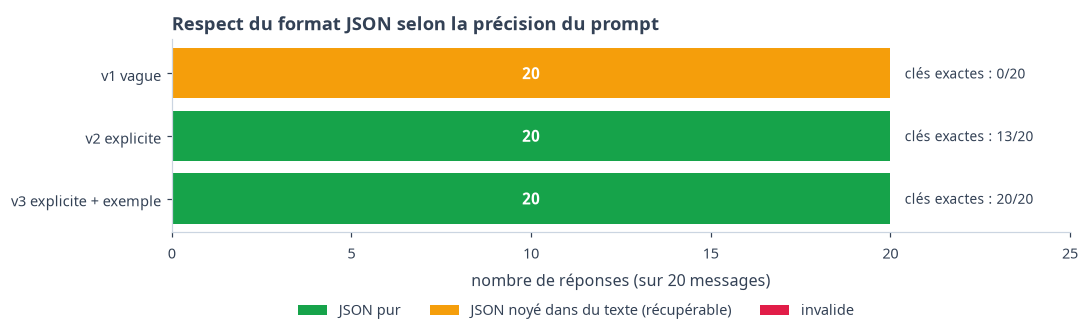

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(tab))
for col, c, lab in [("ok", GREEN, "JSON pur"), ("extrait", AMBER, "JSON noyé dans du texte (récupérable)"),
                    ("invalide", ROSE, "invalide")]:
    ax.barh(range(len(tab)), tab[col], left=left, color=c, label=lab)
    for i, (l, w) in enumerate(zip(left, tab[col])):
        if w:
            ax.text(l + w / 2, i, str(w), ha="center", va="center", color="white", fontweight="bold")
    left += tab[col].values
for i, v in enumerate(tab["clés exactes"]):
    ax.text(20.4, i, f"clés exactes : {v}/20", va="center", fontsize=9)
ax.set_yticks(range(len(tab)), tab.index)
ax.invert_yaxis()
ax.set_xlim(0, 25)
ax.set_xlabel("nombre de réponses (sur 20 messages)")
ax.set_title("Respect du format JSON selon la précision du prompt")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.28), ncol=3)
ax.grid(False)
finish(fig)
plt.show()

**Lecture.** Spécifier les clés et les valeurs permises, puis montrer un exemple, rapproche la
sortie du schéma attendu. Mais même un bon prompt ne **garantit** rien : pour une
application en production, on combine le prompt avec un **analyseur tolérant** (ici
`parse_json_output`, qui récupère un JSON entouré de texte), une validation de schéma, et
éventuellement des nouvelles tentatives ou un décodage contraint (outils cités par le livre :
Outlines, Instructor, Guidance ; voir l'exercice 5.7 et le chapitre 2).

> **À retenir.** Format compact, marqueur de fin, schéma explicite et exemple : quatre leviers
> simples sur le format de sortie. Aucun ne dispense de valider la sortie côté code.

## 4. Fournir suffisamment de contexte (section *Provide Sufficient Context*)

**Le conseil.** Comme un étudiant avec ses notes de cours, un modèle répond mieux avec le
document pertinent ; sans lui, il puise dans sa mémoire et risque d'**halluciner**. L'encadré
du livre sur la restriction des connaissances ajoute : on peut demander de n'utiliser **que**
le contexte, sans garantie absolue.

**L'expérience.** Un règlement intérieur fictif ; 4 questions dont la réponse y figure, 4 dont
la réponse n'y figure pas. Trois prompts : sans contexte, avec contexte, avec contexte et
consigne « réponds uniquement d'après le document, sinon dis : Je ne sais pas ».

In [9]:
REGLEMENT = ("Règlement de la société Tilleul : les bureaux ouvrent à 8h30. Le badge perdu est remplacé "
             "pour 15 euros. Le télétravail est autorisé deux jours par semaine. La cantine ferme à 14h. "
             "Les congés se posent au moins trois semaines à l'avance.")
QA = [("À quelle heure ouvrent les bureaux de Tilleul ?", "8h30", True),
      ("Combien coûte le remplacement d'un badge perdu ?", "15", True),
      ("Combien de jours de télétravail sont autorisés par semaine ?", "deux", True),
      ("À quelle heure ferme la cantine ?", "14h", True),
      ("Quel est le nom du directeur de Tilleul ?", None, False),
      ("Combien de salariés compte Tilleul ?", None, False),
      ("Quel est le mot de passe du wifi des bureaux ?", None, False),
      ("Dans quelle ville se trouve le siège de Tilleul ?", None, False)]
STRICT = "Réponds uniquement d'après le document. Si la réponse n'y figure pas, réponds exactement : Je ne sais pas."

def repondre(q, mode):
    if mode == "sans contexte":
        return llm.chat(q, max_new_tokens=40)
    if mode == "avec contexte":
        return llm.chat(f"Document : {REGLEMENT}\n\nQuestion : {q}", max_new_tokens=40)
    return llm.chat(f"Document : {REGLEMENT}\n\nQuestion : {q}", system=STRICT, max_new_tokens=40)

rows = []
for mode in ["sans contexte", "avec contexte", "contexte + consigne stricte"]:
    for q, rep, answerable in QA:
        out = repondre(q, mode)
        abst = "ne sais pas" in out.lower() or "pas d'information" in out.lower() or "ne figure pas" in out.lower()
        rows.append(dict(mode=mode, question=q, repondable=answerable, sortie=out[:70].replace("\n", " "),
                         correct=(rep is not None and rep in out.lower().replace(" h", "h")), abstention=abst))
ctx = pd.DataFrame(rows)
bilan = ctx.groupby("mode", sort=False).apply(lambda g: pd.Series({
    "réponses justes (répondables, /4)": int(g[g.repondable].correct.sum()),
    "abstentions (non répondables, /4)": int(g[~g.repondable].abstention.sum()),
    "abstentions à tort (répondables, /4)": int(g[g.repondable].abstention.sum())}), include_groups=False)
bilan

,"réponses justes (répondables, /4)","abstentions (non répondables, /4)","abstentions à tort (répondables, /4)"
mode,,,
sans contexte,0,0,1
avec contexte,3,0,0
contexte + consigne stricte,3,3,0


In [10]:
ctx[(ctx["mode"] != "avec contexte") & (~ctx.repondable)][["mode", "question", "sortie"]].head(6)

,mode,question,sortie
4,sans contexte,Quel est le nom du directeur de Tilleul ?,"Le directeur de Tilleul est Jean-Baptiste Tilleul, également connu sou"
5,sans contexte,Combien de salariés compte Tilleul ?,"Je suis désolé, mais je ne peux pas répondre à cette question car elle"
6,sans contexte,Quel est le mot de passe du wifi des bureaux ?,Pourriez-vous me donner plus de détails sur les conditions dans lesque
7,sans contexte,Dans quelle ville se trouve le siège de Tilleul ?,"Le siège de Tilleul est situé à la capitale française de Paris, en Fra"
20,contexte + consigne stricte,Quel est le nom du directeur de Tilleul ?,Je ne sais pas.
21,contexte + consigne stricte,Combien de salariés compte Tilleul ?,Tilleul compte environ 200 salariés.


**Lecture.** Sans contexte, le modèle ne peut pas connaître les faits de cette entreprise
fictive : il esquive ou invente. Avec le document, les questions répondables sont mieux
traitées. Pour les questions **sans réponse** dans le document, la consigne stricte augmente
les abstentions (« Je ne sais pas »), au prix éventuel de quelques abstentions à tort : c'est
le compromis classique entre hallucination et sur-prudence. Le livre rappelle qu'aucune
consigne ne garantit que le modèle s'en tiendra au contexte ; demander de **citer** le passage
utilisé est un autre levier, et la construction du contexte (RAG, recherche web) fait l'objet
du chapitre 6.

> **À retenir.** Le contexte réduit l'hallucination sur les faits qu'il contient ; une
> consigne explicite aide le modèle à s'abstenir quand le contexte est muet, sans garantie.

## 5. Décomposer en sous-tâches (section *Break Complex Tasks into Simpler Subtasks*)

**Le conseil.** Pour une tâche à plusieurs étapes, un prompt par sous-tâche, chaînés,
plutôt qu'un prompt géant. L'exemple du livre est un service client : (1) classer
l'intention, (2) répondre avec des instructions propres à cette intention.

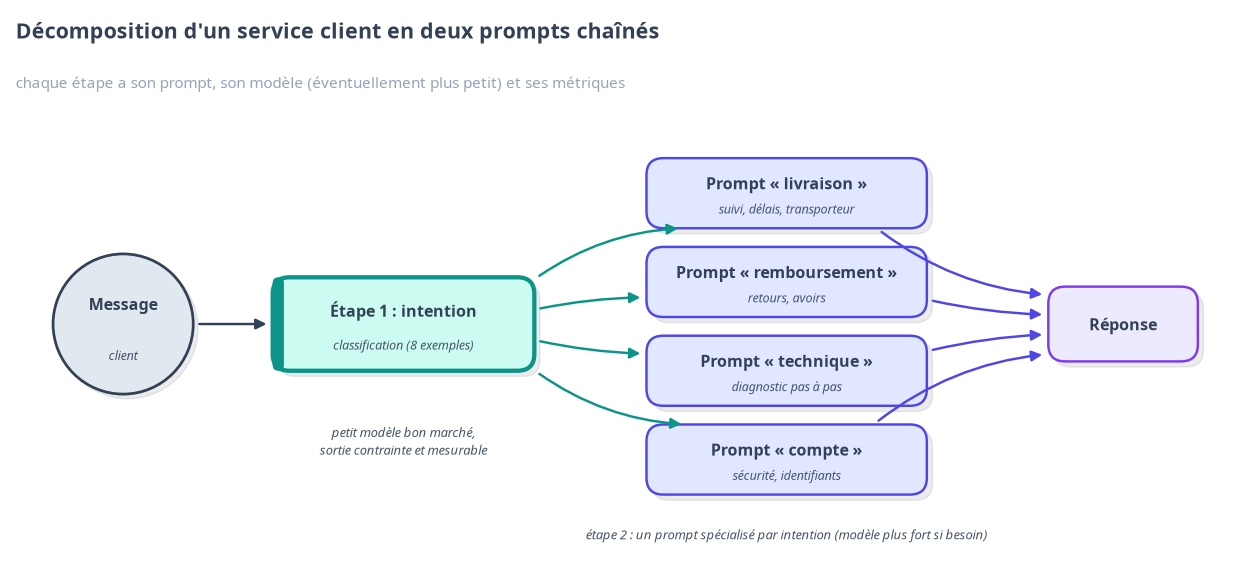

In [11]:
d = Diagram(13, 5.0, title="Décomposition d'un service client en deux prompts chaînés",
            subtitle="chaque étape a son prompt, son modèle (éventuellement plus petit) et ses métriques")
d.box("msg", 1.2, 2.6, "Message", sub="client", color=SLATE, kind="user", w=1.5)
d.box("cls", 4.2, 2.6, "Étape 1 : intention", sub="classification (8 exemples)", color=TEAL, kind="model", w=2.8, h=1.0)
d.box("r1", 8.3, 4.0, "Prompt « livraison »", sub="suivi, délais, transporteur", color=INDIGO, w=3.0, h=0.75)
d.box("r2", 8.3, 3.05, "Prompt « remboursement »", sub="retours, avoirs", color=INDIGO, w=3.0, h=0.75)
d.box("r3", 8.3, 2.1, "Prompt « technique »", sub="diagnostic pas à pas", color=INDIGO, w=3.0, h=0.75)
d.box("r4", 8.3, 1.15, "Prompt « compte »", sub="sécurité, identifiants", color=INDIGO, w=3.0, h=0.75)
d.box("rep", 11.9, 2.6, "Réponse", color=VIOLET, w=1.6, h=0.8)
d.arrow("msg", "cls")
for r, rad in [("r1", -0.15), ("r2", -0.05), ("r3", 0.05), ("r4", 0.15)]:
    d.arrow("cls", r, rad=rad, color=TEAL)
    d.arrow(r, "rep", rad=-rad, color=INDIGO)
d.note(4.2, 1.35, "petit modèle bon marché,\nsortie contrainte et mesurable", fontsize=8.5)
d.note(8.3, 0.35, "étape 2 : un prompt spécialisé par intention (modèle plus fort si besoin)", fontsize=8.5)
d.show()

**Mesure.** On compare la justesse de l'intention dans deux architectures :

- **monolithique** : un seul prompt demande un JSON `{"categorie": ..., "reponse": ...}` ;
- **décomposée** : l'étape 1 classe par score des étiquettes (8 exemples en tours de
  conversation, cours 1), l'étape 2 rédige la réponse avec le prompt de l'intention.

In [12]:
MONO = ('Tu es un agent de service client. Pour le message ci-dessous, réponds UNIQUEMENT par un JSON avec deux clés : '
        '"categorie" (livraison, remboursement, technique ou compte) et "reponse" (une réponse courte et polie au client).')
SPECIALISES = {
    "livraison": "Tu es l'agent livraison. Propose de vérifier le suivi du colis et donne un délai. Deux phrases maximum.",
    "remboursement": "Tu es l'agent remboursements. Explique la procédure de retour ou de remboursement. Deux phrases maximum.",
    "technique": "Tu es l'agent support technique. Propose une première étape de diagnostic. Deux phrases maximum.",
    "compte": "Tu es l'agent comptes clients. Oriente vers la page « Mon compte » et rappelle les règles de sécurité. Deux phrases maximum.",
}
shots8 = P.sample_shots(pool, 8, seed=0)
sub = test[::2]  # 20 messages
rows = []
t_mono = t_deco = 0.0
for x, y in sub:
    t0 = time.perf_counter()
    out = llm.chat(f"{MONO}\n\nMessage : {x}", max_new_tokens=90)
    t_mono += time.perf_counter() - t0
    obj, _ = P.parse_json_output(out)
    cat_mono = str(obj.get("categorie", "?")).lower() if isinstance(obj, dict) else "?"
    t0 = time.perf_counter()
    cat_deco, _ = P.classify(x, shots8)
    rep = llm.chat(x, system=SPECIALISES[cat_deco], max_new_tokens=60)
    t_deco += time.perf_counter() - t0
    rows.append(dict(message=x[:45], vraie=y, monolithique=cat_mono, decomposee=cat_deco, reponse_decomposee=rep[:80]))
deco = pd.DataFrame(rows)
print(f"justesse de l'intention : monolithique {np.mean(deco.monolithique == deco.vraie):.2f} | "
      f"décomposée {np.mean(deco.decomposee == deco.vraie):.2f}")
print(f"temps total : monolithique {t_mono:.1f} s | décomposée {t_deco:.1f} s (20 messages)")
deco.head(4)

justesse de l'intention : monolithique 0.30 | décomposée 0.65
temps total : monolithique 11.0 s | décomposée 10.2 s (20 messages)


,message,vraie,monolithique,decomposee,reponse_decomposee
0,"Ça fait trois semaines que j'attends, c'est u",livraison,compte,compte,"Oui, ça fait trois semaines que vous attendez. C'est une blague."
1,Il manque un article dans le colis que j'ai r,livraison,remboursement,compte,"Pourriez-vous me donner plus d'informations sur le colis? Par exemple, quel est"
2,"Le suivi n'a pas bougé depuis lundi, le paque",livraison,compte,technique,1. Analysez les données de la logique de votre système pour identifier si il y a
3,Est-il possible de recevoir la commande en po,livraison,technique,livraison,"Oui, il est possible de recevoir la commande en point relais plutôt que à domici"


**Lecture.** L'architecture décomposée classe nettement mieux : l'étape 1 est une tâche
simple, contrainte, et on peut lui consacrer des exemples ; dans le prompt monolithique, la
classification est noyée dans la génération (et parfois hors format). La décomposition offre
aussi les bénéfices listés par le livre : **suivi** des sorties intermédiaires, **débogage**
étape par étape, **parallélisation** des étapes indépendantes, prompts plus simples à écrire.

Ses coûts : plus d'appels, donc une **latence perçue** plus grande si l'utilisateur ne voit
pas les étapes intermédiaires. Le coût en tokens n'est pas forcément doublé, car chaque prompt
est plus court et l'étape simple peut tourner sur un modèle moins cher. Le livre cite GoDaddy :
un prompt de service client gonflé à plus de 1 500 tokens a été découpé en prompts plus petits,
plus performants et moins coûteux.

> **À retenir.** Décomposer rend chaque étape plus simple, mesurable et optimisable
> séparément ; on paie en nombre d'appels et en latence perçue.

## 6. Laisser au modèle le temps de réfléchir (section *Give the Model Time to Think*)

**Chaîne de pensée** (*chain-of-thought*, CoT, Wei et al. 2022) : demander au modèle de
raisonner étape par étape avant de répondre. **Auto-critique** (*self-critique*) : lui
demander de vérifier sa propre réponse. Intuition : un transformer dépense une quantité de
calcul **fixe par token** ; générer des étapes intermédiaires lui donne plus de « calcul » et
un brouillon sur lequel s'appuyer.

On compare sur 20 petits problèmes d'arithmétique en français : réponse directe, CoT, puis CoT
suivie d'une auto-critique (second tour de conversation).

In [13]:
DIRECT = "Réponds uniquement par le nombre final, sans explication."
COT = "Réfléchis étape par étape en montrant les calculs, puis termine par une ligne « Réponse : <nombre> »."
CRITIQUE = ("Vérifie chaque calcul de ta réponse précédente. S'il y a une erreur, corrige-la. "
            "Termine par une ligne « Réponse : <nombre> ».")
rows = []
for q, a in P.MATH_PROBLEMS:
    t0 = time.perf_counter()
    d_out = llm.chat(f"{q}\n{DIRECT}", max_new_tokens=12)
    t1 = time.perf_counter()
    c_out = llm.chat(f"{q}\n{COT}", max_new_tokens=300)
    t2 = time.perf_counter()
    msgs = [{"role": "user", "content": f"{q}\n{COT}"}, {"role": "assistant", "content": c_out},
            {"role": "user", "content": CRITIQUE}]
    s_out = llm.chat(msgs, max_new_tokens=300)
    t3 = time.perf_counter()
    rows.append(dict(probleme=q[:40], attendu=a,
                     direct=P.extract_number(d_out), cot=P.extract_number(c_out), critique=P.extract_number(s_out),
                     tok_direct=len(tok(d_out)["input_ids"]), tok_cot=len(tok(c_out)["input_ids"]),
                     tok_critique=len(tok(c_out)["input_ids"]) + len(tok(s_out)["input_ids"]),
                     s_direct=t1 - t0, s_cot=t2 - t1, s_critique=(t2 - t1) + (t3 - t2), exemple_cot=c_out))
raison = pd.DataFrame(rows)
bilan = pd.DataFrame({m: {"précision": np.mean(raison[m] == raison.attendu),
                          "tokens générés (moy.)": raison[f"tok_{m}"].mean(),
                          "latence (s, moy.)": raison[f"s_{m}"].mean()} for m in ["direct", "cot", "critique"]}).T
bilan.index = ["réponse directe", "chaîne de pensée", "CoT + auto-critique"]
bilan.round(2)

,précision,tokens générés (moy.),"latence (s, moy.)"
réponse directe,0.15,2.25,0.02
chaîne de pensée,0.55,183.80,1.06
CoT + auto-critique,0.60,332.10,1.94


In [14]:
print(raison.exemple_cot.iloc[2][:700])

D'accord, let's go through this step-by-step:

1. **Total Passengers Before Changes:**
   - Initial number of passengers: 120

2. **Passengers Descending:**
   - Number of passengers descending: 35

3. **Passengers Entering:**
   - Number of passengers entering: 18

4. **Calculate the New Total:**
   - Total before changes: 120 (initial) + 35 (descending) = 155
   - Total after changes: 155 (before changes) + 18 (entering) = 173

Therefore, the total number of passengers is 173.

**Réponse:** 173


Une chaîne de pensée n'est pas toujours juste : on y voit parfois une étape fausse (par exemple
des passagers qui descendent **ajoutés** au lieu d'être retranchés) qui contamine la réponse.
Elle a toutefois l'avantage de rendre l'erreur **visible** et donc diagnosticable.

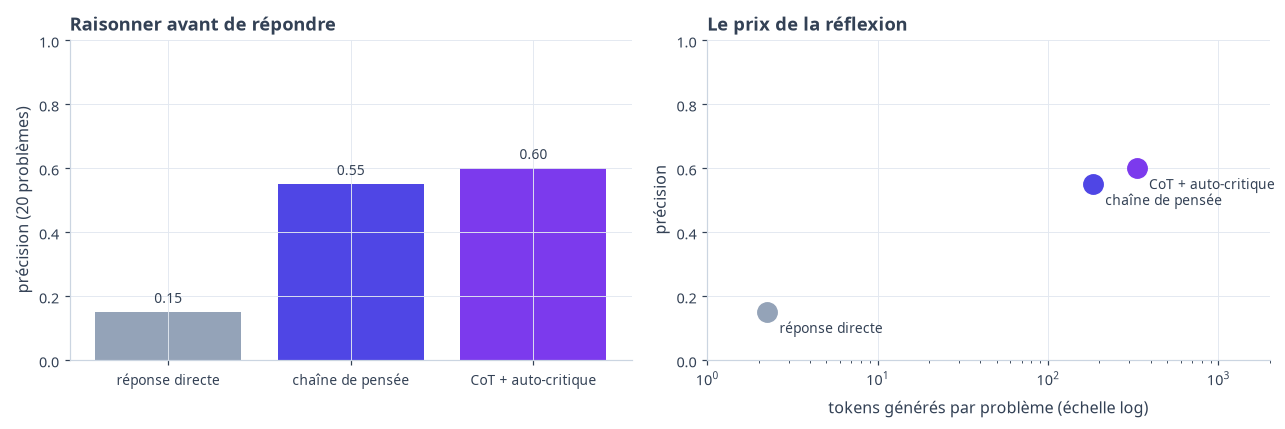

après auto-critique juste,False,True
CoT juste,,
False,7,2
True,1,10


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
cols = [GRAY, INDIGO, VIOLET]
ax.bar(bilan.index, bilan["précision"], color=cols)
annotate_bars(ax, "{:.2f}")
ax.set_ylim(0, 1)
ax.set_ylabel("précision (20 problèmes)")
ax.set_title("Raisonner avant de répondre")
ax.tick_params(axis="x", labelsize=9)
ax = axes[1]
for (nom, r), c in zip(bilan.iterrows(), cols):
    ax.scatter(r["tokens générés (moy.)"], r["précision"], s=160, color=c, zorder=3)
    ax.annotate(nom, (r["tokens générés (moy.)"], r["précision"]), textcoords="offset points", xytext=(8, -14), fontsize=9)
ax.set_xscale("log")
ax.set_xlim(1, 2000)
ax.set_ylim(0, 1)
ax.set_xlabel("tokens générés par problème (échelle log)")
ax.set_ylabel("précision")
ax.set_title("Le prix de la réflexion")
finish(fig)
plt.show()

trans = pd.crosstab(raison.cot == raison.attendu, raison.critique == raison.attendu,
                    rownames=["CoT juste"], colnames=["après auto-critique juste"])
trans

**Lecture.**

- La **chaîne de pensée** fait un bond de précision spectaculaire par rapport à la réponse
  directe : le petit modèle est incapable de « calculer de tête » une opération en deux
  étapes, mais il sait la dérouler par écrit. Le prix : des dizaines de fois plus de tokens
  générés, donc de coût et de latence (le livre insiste sur ce point pour les applications
  interactives).
- L'**auto-critique** n'apporte pas de gain fiable sur ce modèle : le tableau de transitions
  montre combien de réponses justes deviennent fausses et inversement. Un modèle de 0,5 B
  « vérifie » mal ses propres calculs ; l'auto-critique est plus utile sur des modèles forts
  ou avec un vérificateur externe (exécuter le calcul, un juge plus fort : chapitre 3).

> **À retenir.** La chaîne de pensée est l'une des techniques les plus robustes d'un modèle à
> l'autre ; elle se paie en tokens et en latence. L'auto-critique se mesure au cas par cas :
> un modèle faible peut « corriger » une bonne réponse en mauvaise.

## 7. Itérer, organiser et versionner les prompts (sections *Iterate on Your Prompts*, *Organize and Version Prompts*)

**Le conseil.** Itérer systématiquement : **versionner** les prompts, standardiser métrique et
données d'évaluation, évaluer chaque prompt dans le système complet. Séparer les prompts du
code (réutilisabilité, tests, lisibilité, collaboration avec les experts métier), leur
associer des **métadonnées** (modèle, application, auteur, paramètres d'échantillonnage) et,
quand plusieurs applications partagent un prompt, utiliser un **catalogue** qui versionne
chaque prompt indépendamment du code : une équipe peut alors rester sur une ancienne version.

Le module fournit un petit registre, `PromptRegistry`, qui implémente ces idées : versions
numérotées, empreinte de contenu (refus des doublons), épinglage par application, journal de
métriques, diff entre versions, sérialisation JSON.

In [16]:
reg = P.PromptRegistry()
v1 = reg.register("intention_client", P.INTENT_DESCRIPTION, author="équipe support",
                  application="tri des tickets", note="version initiale, zéro exemple")
DESC_V2 = (P.INTENT_DESCRIPTION + " Un problème de colis (retard, colis abîmé, article manquant, frais de port) "
           "relève de livraison, même si le client parle d'argent. Un problème de connexion ou d'identifiant relève de compte.")
v2 = reg.register("intention_client", DESC_V2, author="équipe support", application="tri des tickets",
                  note="précise les frontières livraison / remboursement / compte")
v3 = reg.register("intention_client", DESC_V2 + " ", author="équipe support", application="tri des tickets",
                  note="v2 + 8 exemples en tours de conversation (jeu figé, graine 0)")
# évaluation de chaque version sur le même jeu de test
reg.log_metric("intention_client", 1, "precision", P.accuracy_at_k(test, [], description=v1.text))
reg.log_metric("intention_client", 2, "precision", P.accuracy_at_k(test, [], description=v2.text))
reg.log_metric("intention_client", 3, "precision", P.accuracy_at_k(test, shots8, description=v3.text))
reg.pin("intention_client", "application mobile", 1)  # l'équipe mobile reste sur v1 pour l'instant
reg.table()

,nom,version,empreinte,modele,auteur,note,precision
0,intention_client,1,98121e7a53,Qwen2.5-0.5B-Instruct,équipe support,"version initiale, zéro exemple",0.475
1,intention_client,2,d4c7e5c18c,Qwen2.5-0.5B-Instruct,équipe support,précise les frontières livraison / remboursement / compte,0.400
2,intention_client,3,108b4c025f,Qwen2.5-0.5B-Instruct,équipe support,"v2 + 8 exemples en tours de conversation (jeu figé, graine 0)",0.625


In [17]:
print(reg.diff("intention_client", 1, 2))
print("\nversion servie à l'application mobile :", reg.get("intention_client", app="application mobile").version)
print("version servie par défaut           :", reg.get("intention_client").version)
print("meilleure version (précision)       :", reg.best("intention_client", "precision").version)
print("\nextrait du JSON du catalogue :\n", reg.to_json()[:420], "...")

--- intention_client v1
+++ intention_client v2
@@ -1 +1 @@
-Tu es un assistant de service client. Classe chaque message de client dans une seule catégorie parmi : livraison, remboursement, technique, compte. Réponds uniquement par le nom de la catégorie.
+Tu es un assistant de service client. Classe chaque message de client dans une seule catégorie parmi : livraison, remboursement, technique, compte. Réponds uniquement par le nom de la catégorie. Un problème de colis (retard, colis abîmé, article manquant, frais de port) relève de livraison, même si le client parle d'argent. Un problème de connexion ou d'identifiant relève de compte.

version servie à l'application mobile : 1
version servie par défaut           : 3
meilleure version (précision)       : 3

extrait du JSON du catalogue :
 {
 "prompts": {
  "intention_client": [
   {
    "name": "intention_client",
    "version": 1,
    "text": "Tu es un assistant de service client. Classe chaque message de client dans une seule catégori

Le tableau réserve une surprise instructive : la v2, censée clarifier les frontières entre
catégories, peut faire **moins bien** que la v1 en zéro-shot. Une consigne plus longue n'aide
pas toujours un petit modèle ; sans mesure, on aurait déployé une régression. C'est
l'argument central du livre pour versionner et évaluer chaque itération.

Remarquez que la v3 diffère de la v2 par un espace final dans le texte : son empreinte change,
donc le registre l'accepte comme nouvelle version (une version doit être identifiable par son
contenu exact). En pratique, les exemples few-shot font partie du prompt et devraient être
stockés **dans** l'entrée du catalogue, avec les paramètres d'échantillonnage et le schéma de
sortie attendu (comme le format Dotprompt de Firebase cité par le livre).

> **À retenir.** Un prompt est un artefact logiciel : versionné, accompagné de métadonnées et
> de ses métriques d'évaluation, épinglable par application. Le registre rend les itérations
> traçables et réversibles.

## 8. Outils d'ingénierie de prompts et optimisation automatique (section *Evaluate Prompt Engineering Tools*)

Des outils comme DSPy ou OpenPrompt cherchent automatiquement le prompt (ou la chaîne de
prompts) qui maximise une métrique sur des données d'évaluation, à la manière de l'AutoML ;
Promptbreeder fait « muter » des prompts avec un modèle, TextGrad propage des critiques
textuelles. Le livre met en garde sur deux points : les **appels cachés** qui font exploser la
facture, et les **erreurs** des outils eux-mêmes (mauvais gabarit, coquilles dans les prompts
par défaut). D'où le conseil : commencer sans outil, et toujours inspecter les prompts générés.

**Calcul du nombre d'appels.** Pour $V$ variantes de prompt évaluées sur $N$ exemples, avec
$a$ appels par exemple (générer, valider, noter) et $R$ tours d'optimisation :
$$\text{appels} = R \times V \times N \times a.$$

In [18]:
scenarios = pd.DataFrame([
    dict(scenario="exemple du livre", tours=1, variantes=10, exemples=30, appels_par_exemple=1),
    dict(scenario="+ validation et notation", tours=1, variantes=10, exemples=30, appels_par_exemple=3),
    dict(scenario="optimisation sur 5 tours", tours=5, variantes=10, exemples=30, appels_par_exemple=3),
    dict(scenario="évolution (20 générations x 20 prompts)", tours=20, variantes=20, exemples=50, appels_par_exemple=3),
])
scenarios["appels"] = scenarios.tours * scenarios.variantes * scenarios.exemples * scenarios.appels_par_exemple
scenarios["coût ($, 1 000 tokens/appel à 2 $/M)"] = (scenarios.appels * 1000 * 2 / 1e6).round(2)
scenarios

,scenario,tours,variantes,exemples,appels_par_exemple,appels,"coût ($, 1 000 tokens/appel à 2 $/M)"
0,exemple du livre,1,10,30,1,300,0.6
1,+ validation et notation,1,10,30,3,900,1.8
2,optimisation sur 5 tours,5,10,30,3,4500,9.0
3,évolution (20 générations x 20 prompts),20,20,50,3,60000,120.0


**Mini-optimisation automatique et « malédiction du vainqueur ».** Faisons une recherche
aléatoire sur 12 configurations (formulation x nombre d'exemples x tirage), sélectionnons la
meilleure sur un jeu de **développement** de 20 messages, puis mesurons-la sur 20 messages de
**test** jamais vus.

In [19]:
dev, test2 = test[0::2], test[1::2]
FORMULATIONS = {"originale": P.INTENT_DESCRIPTION, "v2 (frontières)": DESC_V2,
                "courte": "Catégorie du message ? livraison, remboursement, technique ou compte."}
rng = np.random.default_rng(0)
configs = [(f, int(k), int(s)) for f in FORMULATIONS for k, s in zip(rng.choice([0, 4, 8, 12], 4), rng.integers(0, 50, 4))]
res = []
for f, k, s in configs:
    shots = P.sample_shots(pool, k, seed=s)
    res.append(dict(formulation=f, k=k, graine=s,
                    dev=P.accuracy_at_k(dev, shots, description=FORMULATIONS[f]),
                    test=P.accuracy_at_k(test2, shots, description=FORMULATIONS[f])))
res = pd.DataFrame(res).sort_values("dev", ascending=False).reset_index(drop=True)
res.head(6)

,formulation,k,graine,dev,test
0,originale,12,15,0.75,0.75
1,originale,8,2,0.70,0.65
2,v2 (frontières),12,36,0.70,0.75
3,originale,8,3,0.65,0.65
4,v2 (frontières),12,30,0.65,0.75
5,originale,4,0,0.60,0.70


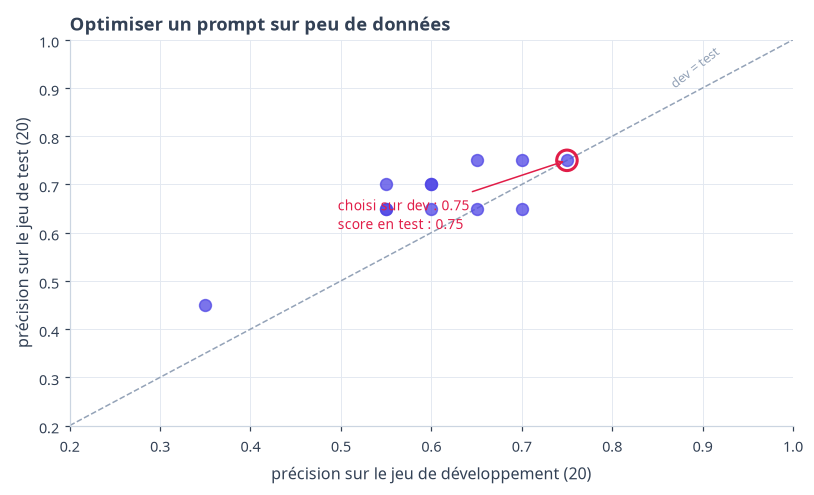

corrélation dev/test : 0.83 ; écart dev - test de la configuration choisie : +0.00
IC 95 % de Wilson de son score en test (20 messages) : [0.53, 0.89]
écart dev - test moyen des 3 meilleures configurations sur dev : -0.00


In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(res.dev, res.test, s=60, color=INDIGO, alpha=0.75, zorder=3)
best = res.iloc[0]
ax.scatter([best.dev], [best.test], s=180, facecolor="none", edgecolor=ROSE, lw=2, zorder=4)
ax.annotate(f"choisi sur dev : {best.dev:.2f}\nscore en test : {best.test:.2f}", (best.dev, best.test),
            textcoords="offset points", xytext=(-150, -45), fontsize=9, color=ROSE,
            arrowprops=dict(arrowstyle="->", color=ROSE))
lims = [0.2, 1.0]
ax.plot(lims, lims, "--", color=GRAY, lw=1)
ax.text(0.86, 0.9, "dev = test", color=GRAY, fontsize=8.5, rotation=38)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("précision sur le jeu de développement (20)")
ax.set_ylabel("précision sur le jeu de test (20)")
ax.set_title("Optimiser un prompt sur peu de données")
finish(fig)
plt.show()
lo, hi = P.wilson_interval(int(round(best.test * 20)), 20)
print(f"corrélation dev/test : {np.corrcoef(res.dev, res.test)[0, 1]:.2f} ; "
      f"écart dev - test de la configuration choisie : {best.dev - best.test:+.2f}")
print(f"IC 95 % de Wilson de son score en test (20 messages) : [{lo:.2f}, {hi:.2f}]")
print(f"écart dev - test moyen des 3 meilleures configurations sur dev : {(res.dev - res.test).head(3).mean():+.2f}")

**Lecture.** La configuration retenue est celle qui a le meilleur score **sur le jeu de
développement**, ce qui est en partie de la chance : avec 20 exemples, chaque message vaut 5
points et l'intervalle de confiance du score couvre une vingtaine de points. Selon le tirage,
le vainqueur conserve son score en test ou le perd : en moyenne, sélectionner le maximum de
scores bruités surestime la performance réelle (c'est la « malédiction du vainqueur », un
surapprentissage du prompt aux données d'évaluation). Ici, la corrélation dev/test est
élevée parce que les grandes différences (nombre d'exemples) dominent le bruit ; entre
configurations proches, c'est le bruit qui décide. Les outils d'optimisation automatique
amplifient ce risque : ils essaient beaucoup de variantes, donc trouvent forcément une
variante chanceuse. Remèdes : des jeux d'évaluation plus grands, un jeu de test tenu à
l'écart, et des intervalles de confiance (exercice 5.9).

> **À retenir.** Un outil d'ingénierie de prompts est un optimiseur : il coûte des appels
> (souvent cachés) et surapprend aux données d'évaluation. Inspecter ses prompts, compter ses
> appels et tenir un jeu de test à l'écart.

## Synthèse

| Pratique | Ce qu'on a mesuré sur Qwen2.5-0.5B | Coût |
|---|---|---|
| Instructions explicites | format respecté bien plus souvent, sorties plus courtes | quelques tokens de consigne |
| Persona | la note espérée change avec le point de vue | négligeable |
| Format et marqueurs | étiquette directe avec la flèche ; JSON plus conforme avec schéma et exemple | quelques tokens |
| Contexte suffisant | réponses justes sur les faits du document, plus d'abstentions avec consigne stricte | tokens du document |
| Décomposition | intention mieux classée que dans un prompt monolithique | plus d'appels, latence perçue |
| Chaîne de pensée | bond de précision en arithmétique | des dizaines de fois plus de tokens générés |
| Auto-critique | pas de gain fiable sur un petit modèle | double l'appel |
| Versionnage | itérations traçables, épinglage par application | discipline |

Liens : évaluation et juges IA (chapitre 3), sorties structurées et échantillonnage
(chapitre 2), RAG pour le contexte (chapitre 6), latence et coût (chapitre 9). Le cours 4
change de point de vue : comment un **attaquant** exploite ces mêmes prompts.

In [21]:
llm.free_gpu()